C:\Users\saksham\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.3124 - loss: 1.9172
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.3741 - loss: 1.7494
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.3975 - loss: 1.6805
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.4175 - loss: 1.6391
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.4307 - loss: 1.5974
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.4407 - loss: 1.5729
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.4527 - loss: 1.5465
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.4587 - loss: 1.5292
Epoch 9/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.4617 - loss: 1.5127
Epoch 10/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.4630 - loss: 1.5029
Epoch 11/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.4712 - loss: 1.4918
Epoch 12/20
1250/1250 ━━━━━━━━

array([<Axes: >, <Axes: >], dtype=object)

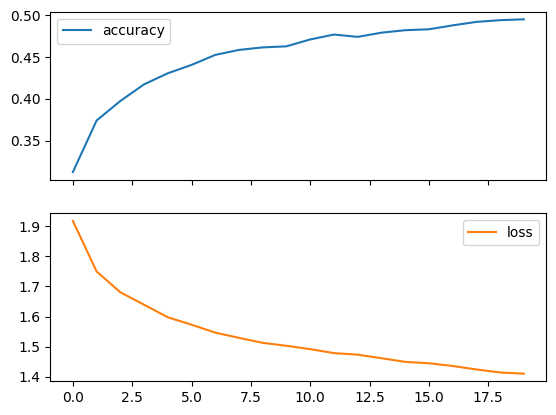

In [1]:

import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split

# Load data
train = pd.read_csv("LP IV Updated Datasets/FNN and CNN/CIFAR10/cifar-10.csv", dtype="uint8")
train, test = train_test_split(train, test_size=0.2)

y_train = train.pop("label")
y_test = test.pop("label")
x_train = train.to_numpy("float32") / 255
x_test = test.to_numpy("float32") / 255

# Create model
model = Sequential([
    Dense(256, activation='relu', input_shape=(3072,)),
    Dense(10, activation='softmax')
])

# Compile
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train
history = model.fit(x_train, y_train, epochs=20)

# Evaluate
loss, accuracy = model.evaluate(x_test, y_test)
print("Accuracy:", accuracy * 100, "%")

# Plot
pd.DataFrame(history.history).plot(subplots=True)
